# Classification with Least Squares

CSC604 Module 6 introduces classification and asks how a regression model can be used for a
classification task. The simplest answer is **least-squares classification**:

1. encode the two classes as $-1$ and $+1$;
2. fit an ordinary least-squares line (or hyperplane);
3. predict the class from the sign of the fitted value.

This notebook shows the method, compares it with logistic regression, and explains why it is a
useful baseline but not a complete classification method.

## Learning objectives

By the end of this notebook you can:

- fit a least-squares classifier and turn its output into class labels;
- compare its decision boundary and metrics with logistic regression;
- explain why squared error is not a natural loss for class labels;
- recognise when a linear classifier is too restrictive.

## 1. The idea

For a binary target $y_i \in \{-1,+1\}$ and features $x_i$, least-squares classification fits

$$
\hat{y}_i = x_i^\top w + b
$$

by minimising $\sum_i (y_i - \hat{y}_i)^2$, exactly as in linear regression. The predicted class is

$$
\hat{c}_i =
\begin{cases}
+1 & \hat{y}_i \ge 0,\\
-1 & \hat{y}_i < 0.
\end{cases}
$$

The fitted values are not probabilities. A value of $0.2$ means "slightly on the positive side of
the boundary", not "20% probability of class +1".

### Connection to other methods

Least-squares classification is closely related to linear discriminant analysis (LDA) under
balanced classes and a shared covariance structure. It is also a useful bridge to logistic
regression and the perceptron: all three learn a linear decision boundary, but they optimise
different losses.

### What can go wrong

- predictions are unbounded and can lie far outside $[-1,1]$;
- a few high-leverage points can move the boundary a lot;
- squared error treats all mistakes symmetrically and is sensitive to confident errors;
- there is no calibrated probability output;
- class imbalance shifts the effective threshold;
- the boundary is still linear, so non-linear class structure remains unsolved.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_moons
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

RANDOM_STATE = 42

## 2. Helpers for metrics and decision boundaries

In [2]:
def classification_metrics(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_score is not None:
        result["roc_auc"] = roc_auc_score(y_true, y_score)
    return result


def plot_boundary(ax, score_function, threshold, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    scores = score_function(np.c_[xx.ravel(), yy.ravel()])
    labels = (scores >= threshold).astype(int).reshape(xx.shape)

    ax.contourf(xx, yy, labels, alpha=0.2, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=24)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(title)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

## 3. A linearly separable-ish two-dimensional example

`make_classification` gives us a controlled binary problem. One class is encoded as $+1$ and the
other as $-1$ for the least-squares fit.

In [3]:
X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.6,
    flip_y=0.03,
    random_state=RANDOM_STATE,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Class counts (train):", np.bincount(y_train))

Training shape: (210, 2)
Test shape: (90, 2)
Class counts (train): [104 106]


In [4]:
y_train_signed = np.where(y_train == 1, 1, -1)

least_squares = LinearRegression().fit(X_train, y_train_signed)
logistic = LogisticRegression(max_iter=1000).fit(X_train, y_train)

ls_test_score = least_squares.predict(X_test)
ls_test_pred = (ls_test_score >= 0).astype(int)

log_test_score = logistic.predict_proba(X_test)[:, 1]
log_test_pred = logistic.predict(X_test)

print("Least-squares coefficients:", least_squares.coef_.round(3))
print("Least-squares intercept:", round(least_squares.intercept_, 3))
print("Logistic coefficients:", logistic.coef_[0].round(3))
print("Logistic intercept:", round(logistic.intercept_[0], 3))
print()
print("Least-squares score range on test set:", ls_test_score.min().round(3), "to", ls_test_score.max().round(3))

Least-squares coefficients: [0.14  0.503]
Least-squares intercept: -0.214
Logistic coefficients: [0.561 2.428]
Logistic intercept: -0.778

Least-squares score range on test set: -1.363 to 1.62


In [5]:
metrics_table = pd.DataFrame(
    {
        "least_squares": classification_metrics(y_test, ls_test_pred, ls_test_score),
        "logistic": classification_metrics(y_test, log_test_pred, log_test_score),
    }
).T

metrics_table.round(3)

,accuracy,precision,recall,specificity,f1,roc_auc
least_squares,0.933,0.953,0.911,0.956,0.932,0.96
logistic,0.933,0.953,0.911,0.956,0.932,0.96


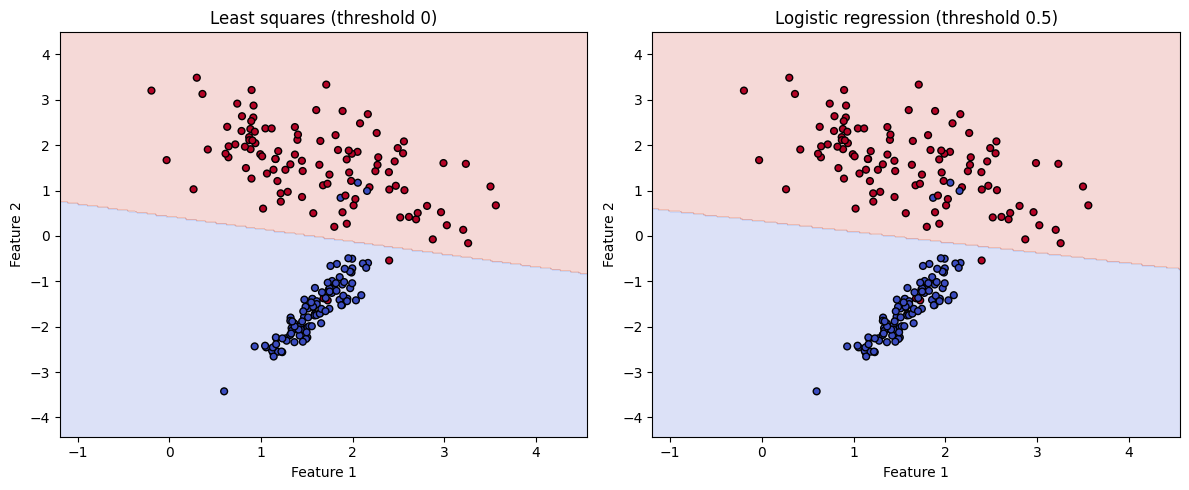

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_boundary(
    axes[0],
    lambda points: least_squares.predict(points),
    0.0,
    X_train,
    y_train,
    "Least squares (threshold 0)",
)
plot_boundary(
    axes[1],
    lambda points: logistic.predict_proba(points)[:, 1],
    0.5,
    X_train,
    y_train,
    "Logistic regression (threshold 0.5)",
)

plt.tight_layout()
plt.show()

On a roughly linearly separable problem the two boundaries can be very close. The least-squares
classifier works here because the classes are balanced and the fitted surface crosses zero near the
true separation. That is not a general guarantee.

Notice also that the least-squares scores are not probabilities. They can be greater than $1$ or
less than $-1$, and they do not have to be calibrated.

## 4. A non-linear problem exposes the limitation

`make_moons` creates two interleaving crescents. A single straight line cannot separate them well.
Both least-squares classification and logistic regression are linear classifiers, so both leave
many errors. A non-linear model such as an RBF-kernel SVM can bend the boundary.

In [7]:
X_moons, y_moons = make_moons(n_samples=400, noise=0.22, random_state=RANDOM_STATE)

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_moons, y_moons, test_size=0.3, stratify=y_moons, random_state=RANDOM_STATE
)

ls_moons = LinearRegression().fit(Xm_train, np.where(ym_train == 1, 1, -1))
log_moons = LogisticRegression(max_iter=1000).fit(Xm_train, ym_train)
svc_moons = SVC(kernel="rbf", gamma="scale").fit(Xm_train, ym_train)

ls_moons_pred = (ls_moons.predict(Xm_test) >= 0).astype(int)
log_moons_pred = log_moons.predict(Xm_test)
svc_moons_pred = svc_moons.predict(Xm_test)

moon_metrics = pd.DataFrame(
    {
        "least_squares": classification_metrics(
            ym_test, ls_moons_pred, ls_moons.predict(Xm_test)
        ),
        "logistic": classification_metrics(
            ym_test, log_moons_pred, log_moons.predict_proba(Xm_test)[:, 1]
        ),
        "rbf_svm": classification_metrics(
            ym_test, svc_moons_pred, svc_moons.decision_function(Xm_test)
        ),
    }
).T

moon_metrics.round(3)

,accuracy,precision,recall,specificity,f1,roc_auc
least_squares,0.900,0.929,0.867,0.933,0.897,0.966
logistic,0.892,0.927,0.850,0.933,0.887,0.966
rbf_svm,0.958,0.966,0.950,0.967,0.958,0.987


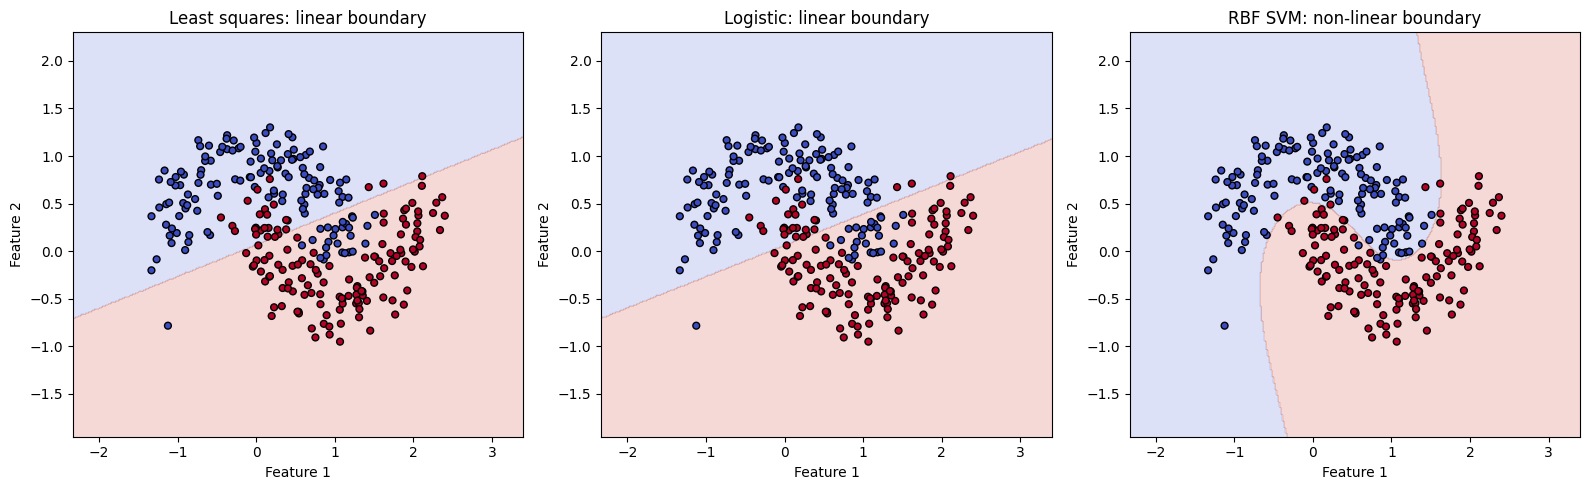

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_boundary(
    axes[0],
    lambda points: ls_moons.predict(points),
    0.0,
    Xm_train,
    ym_train,
    "Least squares: linear boundary",
)
plot_boundary(
    axes[1],
    lambda points: log_moons.predict_proba(points)[:, 1],
    0.5,
    Xm_train,
    ym_train,
    "Logistic: linear boundary",
)
plot_boundary(
    axes[2],
    lambda points: svc_moons.predict(points),
    0.5,
    Xm_train,
    ym_train,
    "RBF SVM: non-linear boundary",
)

plt.tight_layout()
plt.show()

The comparison isolates the real issue: least-squares classification is a **linear** classifier.
Its weakness on the moons data is shared with logistic regression. Changing the loss alone does
not create a non-linear boundary.

## 5. Least squares versus logistic regression

| Aspect | Least-squares classification | Logistic regression |
| --- | --- | --- |
| Output | Unbounded score | Probability in $(0,1)$ |
| Loss | Squared error | Bernoulli log-likelihood |
| Decision rule | Sign of fitted value | Probability threshold |
| Probability calibration | None | Built-in model |
| Sensitivity to outliers | High | Lower, but not immune |
| Boundary | Linear | Linear (unless features are expanded) |
| Typical role | Baseline / historical bridge | Standard binary classifier |

If you need probabilities, inference, or a principled likelihood, use logistic regression. If you
need a very fast baseline on a large, roughly balanced, linearly separable problem, least squares
can still be a reasonable first check.

## Summary

- Encode binary labels as $-1/+1$, fit OLS, and classify by the sign.
- The method is simple and closely related to LDA, but it is not a probabilistic classifier.
- Squared error is sensitive to outliers and unbounded predictions.
- It remains a linear classifier, so it cannot solve non-linear class structure.
- Logistic regression is usually the better default for binary classification.

## Exercises

1. Repeat the first experiment with labels encoded as $0/1$ and threshold at $0.5$. Compare the
   boundary with the $-1/+1$ encoding.
2. Add one extreme outlier to the training data and measure how much the least-squares boundary
   moves. Repeat for logistic regression.
3. Change the class balance with `weights=` in `make_classification` and compare accuracy,
   precision, and recall.
4. Fit least-squares classification on polynomial features and compare it with logistic regression
   on the same expanded features.
5. Explain in your own words why a fitted value of $1.7$ is not a probability.